In [6]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image


In [7]:
MODEL_PATH = "../parkinsons_handwriting_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("✅ Model loaded successfully")


✅ Model loaded successfully


In [8]:
# From training notebook:
# Class order used in training: ['Healthy', 'Parkinson']

class_names = ['Healthy', 'Parkinson']
print("Class names:", class_names)


Class names: ['Healthy', 'Parkinson']


In [10]:
def preprocess_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array


In [11]:
def show_preprocessed_image(img_path):
    img_array = preprocess_image(img_path)

    # Remove batch dimension
    img = img_array[0]

    plt.imshow(img)
    plt.title("Preprocessed Image (224x224, normalized)")
    plt.axis("off")
    plt.show()


In [39]:
def predict_handwriting(img_path):
    img_array = preprocess_image(img_path)
    probs = model.predict(img_array)[0]

    healthy_prob = probs[0] * 100
    parkinson_prob = probs[1] * 100

    label = class_names[np.argmax(probs)]
    confidence = np.max(probs) * 100

    print("Healthy probability   :", f"{healthy_prob:.2f}%")
    print("Parkinson probability :", f"{parkinson_prob:.2f}%")
    print("\nFinal Prediction:", label)
    print(f"Confidence: {confidence:.2f}%")

    return label, confidence


In [40]:
def clinical_predict(img_path, low=0.3, high=0.7):
    img_array = preprocess_image(img_path)
    probs = model.predict(img_array)[0]

    parkinson_prob = probs[1]

    if parkinson_prob >= high:
        label = "Parkinson"
        confidence = parkinson_prob * 100
    elif parkinson_prob <= low:
        label = "Healthy"
        confidence = (1 - parkinson_prob) * 100
    else:
        label = "Uncertain"
        confidence = parkinson_prob * 100

    print("Healthy probability   :", f"{probs[0]*100:.2f}%")
    print("Parkinson probability :", f"{probs[1]*100:.2f}%")
    print("\nClinical Prediction:", label)
    print(f"Confidence: {confidence:.2f}%")

    return label, confidence


In [41]:
def show_image(img_path):
    img = Image.open(img_path)
    plt.imshow(img)
    plt.axis("off")
    plt.title("Input Handwriting Image")
    plt.show()


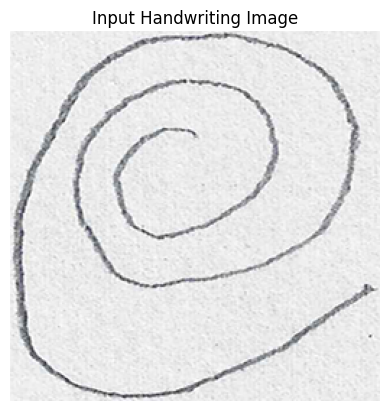

1/1 [==============================] - 0s 110ms/step
Healthy probability   : 10.54%
Parkinson probability : 89.46%

Final Prediction: Parkinson
Confidence: 89.46%
1/1 [==============================] - 0s 120ms/step
Healthy probability   : 10.54%
Parkinson probability : 89.46%

Clinical Prediction: Parkinson
Confidence: 89.46%


('Parkinson', 89.46251273155212)

In [49]:
img_path = r"D:\predictions\Handwriting\dataset\Healthy\Healthy25.png"
show_image(img_path)

# Basic binary prediction
predict_handwriting(img_path)

# OR clinical prediction (recommended)
clinical_predict(img_path)


In [47]:
import os, random

test_dir = r"D:\predictions\Handwriting\dataset\Healthy"  # or Parkinson
samples = random.sample(os.listdir(test_dir), 5)

for img_name in samples:
    print("\n==============================")
    print("Testing:", img_name)
    img_path = os.path.join(test_dir, img_name)
    clinical_predict(img_path)



Testing: Healthy891.png
1/1 [==============================] - 0s 131ms/step
Healthy probability   : 10.41%
Parkinson probability : 89.59%

Clinical Prediction: Parkinson
Confidence: 89.59%

Testing: Healthy141.png
1/1 [==============================] - 0s 121ms/step
Healthy probability   : 9.85%
Parkinson probability : 90.15%

Clinical Prediction: Parkinson
Confidence: 90.15%

Testing: Healthy403.png
1/1 [==============================] - 0s 127ms/step
Healthy probability   : 9.82%
Parkinson probability : 90.18%

Clinical Prediction: Parkinson
Confidence: 90.18%

Testing: Healthy738.png
1/1 [==============================] - 0s 151ms/step
Healthy probability   : 9.77%
Parkinson probability : 90.23%

Clinical Prediction: Parkinson
Confidence: 90.23%

Testing: Healthy1277.png
1/1 [==============================] - 0s 115ms/step
Healthy probability   : 9.69%
Parkinson probability : 90.31%

Clinical Prediction: Parkinson
Confidence: 90.31%


In [1]:
## Confusion Matrix on Test Dataset

In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    auc
)
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
MODEL_PATH = "../parkinsons_handwriting_model.keras"
TEST_DATA_PATH = "../dataset_split/test"

CLASS_NAMES = ["Healthy", "Parkinson"]
IMG_SIZE = (224, 224)

model = tf.keras.models.load_model(MODEL_PATH)
print("✅ Handwriting model loaded")


✅ Handwriting model loaded


In [4]:
true_labels = []
pred_labels = []
pred_probs = []

print("Evaluating handwriting test dataset...\n")

for class_idx, class_name in enumerate(CLASS_NAMES):
    class_dir = os.path.join(TEST_DATA_PATH, class_name)

    if not os.path.exists(class_dir):
        print(f"[WARNING] Missing folder: {class_dir}")
        continue

    files = [f for f in os.listdir(class_dir)
             if f.lower().endswith((".png", ".jpg", ".jpeg"))]

    print(f"[{class_name}] {len(files)} images")

    for img_file in files:
        img_path = os.path.join(class_dir, img_file)

        try:
            img = image.load_img(img_path, target_size=IMG_SIZE)
            img_array = image.img_to_array(img)
            img_array = img_array / 255.0
            img_array = np.expand_dims(img_array, axis=0)

            probs = model.predict(img_array, verbose=0)[0]
            pred_class = np.argmax(probs)        # 0=Healthy, 1=Parkinson

            true_labels.append(class_idx)
            pred_labels.append(pred_class)
            pred_probs.append(probs[1])          # Parkinson probability

        except Exception as e:
            print(f"[ERROR] {img_file}: {e}")

true_labels = np.array(true_labels)
pred_labels = np.array(pred_labels)
pred_probs = np.array(pred_probs)

print(f"\nTotal test images evaluated: {len(true_labels)}")


Evaluating handwriting test dataset...

[Healthy] 164 images
[Parkinson] 164 images

Total test images evaluated: 328


In [5]:
cm = confusion_matrix(true_labels, pred_labels)

acc  = accuracy_score(true_labels, pred_labels)
prec = precision_score(true_labels, pred_labels, zero_division=0)
rec  = recall_score(true_labels, pred_labels, zero_division=0)
f1   = f1_score(true_labels, pred_labels, zero_division=0)

print("="*60)
print("CONFUSION MATRIX")
print("="*60)
print(f"{'':20} Pred Healthy  Pred Parkinson")
print(f"{'Actual Healthy':20} {cm[0,0]:13}  {cm[0,1]:15}")
print(f"{'Actual Parkinson':20} {cm[1,0]:13}  {cm[1,1]:15}")
print("="*60)

print("\nPERFORMANCE METRICS")
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(true_labels, pred_labels, target_names=CLASS_NAMES))


CONFUSION MATRIX
                     Pred Healthy  Pred Parkinson
Actual Healthy                   0              164
Actual Parkinson                 0              164

PERFORMANCE METRICS
Accuracy : 0.5000 (50.00%)
Precision: 0.5000
Recall   : 1.0000
F1-score : 0.6667

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00       164
   Parkinson       0.50      1.00      0.67       164

    accuracy                           0.50       328
   macro avg       0.25      0.50      0.33       328
weighted avg       0.25      0.50      0.33       328



d:\predictions\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\predictions\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\predictions\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


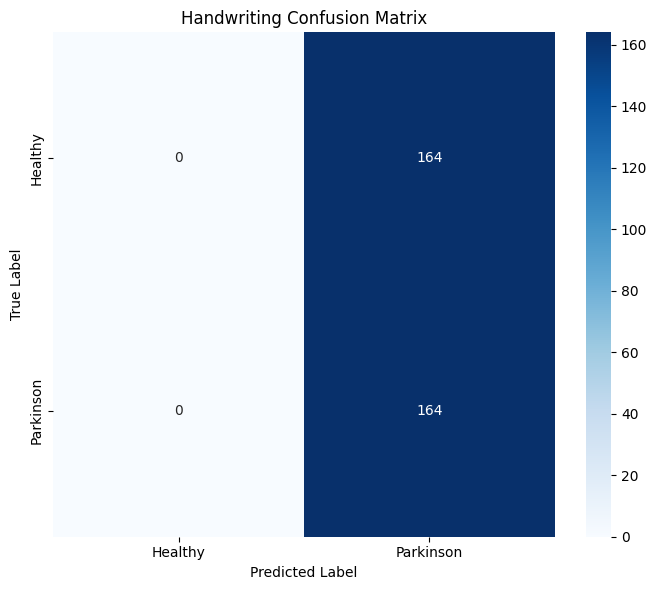

TN: 0
FP: 164
FN: 0
TP: 164


In [6]:
plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Handwriting Confusion Matrix")
plt.tight_layout()
plt.show()

print("TN:", cm[0,0])
print("FP:", cm[0,1])
print("FN:", cm[1,0])
print("TP:", cm[1,1])


In [7]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns


In [8]:
MODEL_PATH = "../parkinsons_handwriting_model.keras"
TRAIN_DATA_PATH = "../dataset_split/train"

CLASS_NAMES = ["Healthy", "Parkinson"]
IMG_SIZE = (224, 224)

model = tf.keras.models.load_model(MODEL_PATH)
print("✅ Model loaded for TRAINING evaluation")


✅ Model loaded for TRAINING evaluation


In [9]:
true_labels = []
pred_labels = []
pred_probs = []

print("Evaluating TRAINING dataset...\n")

for class_idx, class_name in enumerate(CLASS_NAMES):
    class_dir = os.path.join(TRAIN_DATA_PATH, class_name)

    files = [f for f in os.listdir(class_dir)
             if f.lower().endswith((".png", ".jpg", ".jpeg"))]

    print(f"[{class_name}] {len(files)} images")

    for img_file in files:
        img_path = os.path.join(class_dir, img_file)

        img = image.load_img(img_path, target_size=IMG_SIZE)
        img_array = image.img_to_array(img)
        img_array = img_array / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        probs = model.predict(img_array, verbose=0)[0]
        pred_class = np.argmax(probs)

        true_labels.append(class_idx)
        pred_labels.append(pred_class)
        pred_probs.append(probs[1])  # Parkinson probability

true_labels = np.array(true_labels)
pred_labels = np.array(pred_labels)
pred_probs = np.array(pred_probs)

print(f"\nTotal TRAIN images evaluated: {len(true_labels)}")


Evaluating TRAINING dataset...

[Healthy] 1305 images
[Parkinson] 1305 images

Total TRAIN images evaluated: 2610


In [10]:
cm = confusion_matrix(true_labels, pred_labels)

acc  = accuracy_score(true_labels, pred_labels)
prec = precision_score(true_labels, pred_labels, zero_division=0)
rec  = recall_score(true_labels, pred_labels, zero_division=0)
f1   = f1_score(true_labels, pred_labels, zero_division=0)

print("="*60)
print("TRAINING CONFUSION MATRIX")
print("="*60)
print(f"{'':20} Pred Healthy  Pred Parkinson")
print(f"{'Actual Healthy':20} {cm[0,0]:13}  {cm[0,1]:15}")
print(f"{'Actual Parkinson':20} {cm[1,0]:13}  {cm[1,1]:15}")
print("="*60)

print("\nTRAINING PERFORMANCE METRICS")
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nCLASSIFICATION REPORT (TRAIN)")
print(classification_report(true_labels, pred_labels, target_names=CLASS_NAMES))


TRAINING CONFUSION MATRIX
                     Pred Healthy  Pred Parkinson
Actual Healthy                   0             1305
Actual Parkinson                 0             1305

TRAINING PERFORMANCE METRICS
Accuracy : 0.5000 (50.00%)
Precision: 0.5000
Recall   : 1.0000
F1-score : 0.6667

CLASSIFICATION REPORT (TRAIN)
              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00      1305
   Parkinson       0.50      1.00      0.67      1305

    accuracy                           0.50      2610
   macro avg       0.25      0.50      0.33      2610
weighted avg       0.25      0.50      0.33      2610



d:\predictions\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\predictions\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\predictions\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


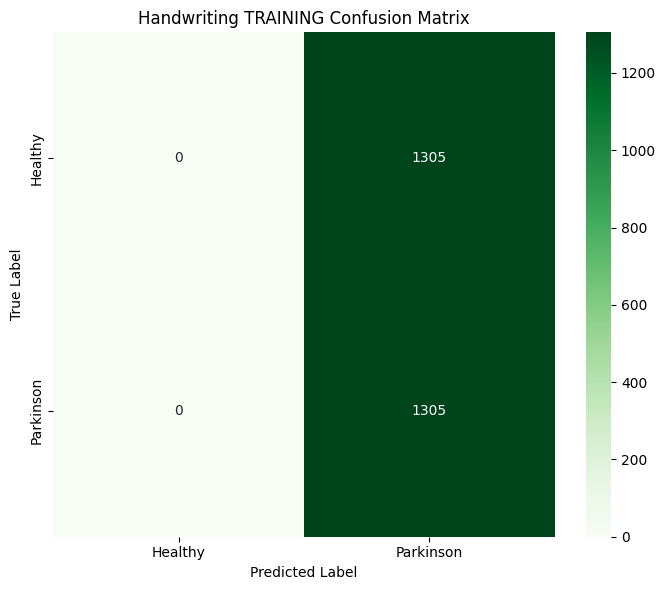

TN: 0
FP: 1305
FN: 0
TP: 1305


In [11]:
plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Handwriting TRAINING Confusion Matrix")
plt.tight_layout()
plt.show()

print("TN:", cm[0,0])
print("FP:", cm[0,1])
print("FN:", cm[1,0])
print("TP:", cm[1,1])
